In [80]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import librosa

In [81]:
df = pd.read_csv("my_gtzan_features.csv")
df.head()

,tempo,spectral_centroid_mean,spectral_centroid_std,spectral_rolloff_mean,spectral_rolloff_std,zero_crossing_rate_mean,zero_crossing_rate_std,rms_mean,rms_std,chroma_stft_mean,...,mfcc_9_mean,mfcc_9_std,mfcc_10_mean,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,nom_fichier,genre
0,123.046875,1784.416546,360.194166,3806.418650,949.383832,0.083066,0.027690,0.130192,0.053201,0.349951,...,10.973775,7.962441,-8.322410,7.861968,8.806787,7.161843,-3.665802,6.422743,blues.00000.wav,blues
1,67.999589,1529.871314,613.197888,3548.986873,1725.338349,0.056044,0.038059,0.095892,0.048724,0.340945,...,11.906445,10.215605,-5.558123,10.257860,5.375942,9.813216,-2.237833,8.056108,blues.00001.wav,blues
2,161.499023,1552.637786,395.649207,3041.089944,884.842654,0.076301,0.031738,0.175494,0.052465,0.363562,...,9.700466,8.236836,-13.115349,7.592525,5.785764,8.037509,-8.899733,7.776661,blues.00002.wav,blues
3,63.024009,1070.110059,429.542379,2185.061787,1222.372310,0.033309,0.020569,0.141139,0.079623,0.404848,...,8.147393,8.439375,-3.195236,10.503592,6.085354,6.941436,-2.476188,7.537466,blues.00003.wav,blues
4,135.999178,1835.507008,585.947299,3581.003346,1253.847208,0.101500,0.044199,0.091540,0.048011,0.308598,...,1.203878,9.989756,-13.085074,8.961199,-2.809849,9.300109,-6.935621,9.466440,blues.00004.wav,blues


In [82]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 43 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   tempo                    1000 non-null   float64
 1   spectral_centroid_mean   1000 non-null   float64
 2   spectral_centroid_std    1000 non-null   float64
 3   spectral_rolloff_mean    1000 non-null   float64
 4   spectral_rolloff_std     1000 non-null   float64
 5   zero_crossing_rate_mean  1000 non-null   float64
 6   zero_crossing_rate_std   1000 non-null   float64
 7   rms_mean                 1000 non-null   float64
 8   rms_std                  1000 non-null   float64
 9   chroma_stft_mean         1000 non-null   float64
 10  chroma_stft_std          1000 non-null   float64
 11  spectral_bandwidth_mean  1000 non-null   float64
 12  spectral_bandwidth_std   1000 non-null   float64
 13  harmony_mean             1000 non-null   float64
 14  harmony_std              1000 non-nu

In [86]:
df=df.drop(["lenght_std","lenght_mean"],axis =1)
df.describe()

,tempo,spectral_centroid_mean,spectral_centroid_std,spectral_rolloff_mean,spectral_rolloff_std,zero_crossing_rate_mean,zero_crossing_rate_std,rms_mean,rms_std,chroma_stft_mean,...,mfcc_8_mean,mfcc_8_std,mfcc_9_mean,mfcc_9_std,mfcc_10_mean,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,119.424661,2201.908469,631.584890,4571.877792,1264.469454,0.103637,0.049371,0.130875,0.048339,0.378696,...,-6.998029,9.196779,7.730703,8.838092,-6.023232,8.482878,4.471887,8.094807,-4.798732,8.038716
std,28.224072,715.936438,266.035677,1574.686981,495.119974,0.041834,0.023437,0.065659,0.026738,0.081704,...,8.284321,1.989684,7.938870,1.896390,6.819009,1.885959,6.717816,1.766198,6.171305,1.796280
min,58.726918,570.150688,89.206350,749.528801,121.686233,0.021701,0.006633,0.005270,0.002069,0.171770,...,-31.656443,5.086445,-12.049384,4.385247,-28.050291,4.627245,-15.806172,4.320407,-27.549044,4.157429
25%,99.384014,1628.001256,429.714464,3381.008722,879.415198,0.070281,0.032848,0.086586,0.030665,0.319462,...,-13.263010,7.741608,1.620157,7.459344,-10.972273,7.152777,-0.551719,6.846061,-9.365386,6.799285
50%,117.453835,2209.457924,581.958628,4658.484331,1215.082615,0.099539,0.044973,0.122397,0.042690,0.383055,...,-7.517142,8.926735,7.148099,8.618674,-5.918071,8.275759,3.889783,7.878847,-4.200263,7.811946
75%,135.999178,2691.943500,782.453792,5534.110286,1598.693138,0.132007,0.060247,0.175723,0.059856,0.435605,...,-0.383880,10.429182,14.396436,9.951148,-0.991921,9.547414,9.707966,9.067629,-0.157045,8.929124
max,234.907670,4434.948743,1742.272546,8676.447535,2942.959745,0.274829,0.169380,0.397851,0.166458,0.663541,...,19.130112,17.852739,27.228352,18.811926,17.423235,24.301636,23.026806,17.253351,13.060921,17.016661


In [87]:
print('Différents genres :')
print(list(df["genre"].unique()))

Différents genres :
['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


#                                 Analyse exploratoire



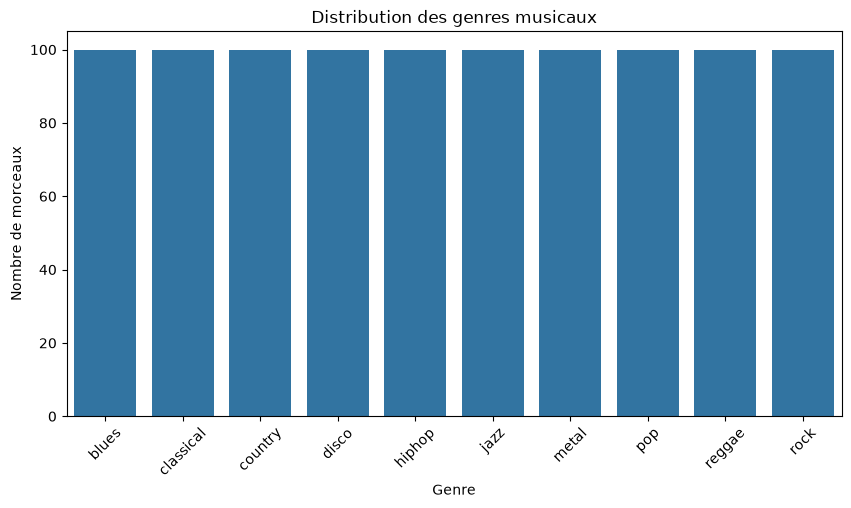

In [213]:
#distribution du genre
plt.figure(figsize=(10,5))
sns.countplot(x="genre",data=df,order=df["genre"].value_counts().index)
plt.title("Distribution des genres musicaux")
plt.xlabel("Genre")
plt.ylabel("Nombre de morceaux")
plt.xticks(rotation=45)
plt.show()

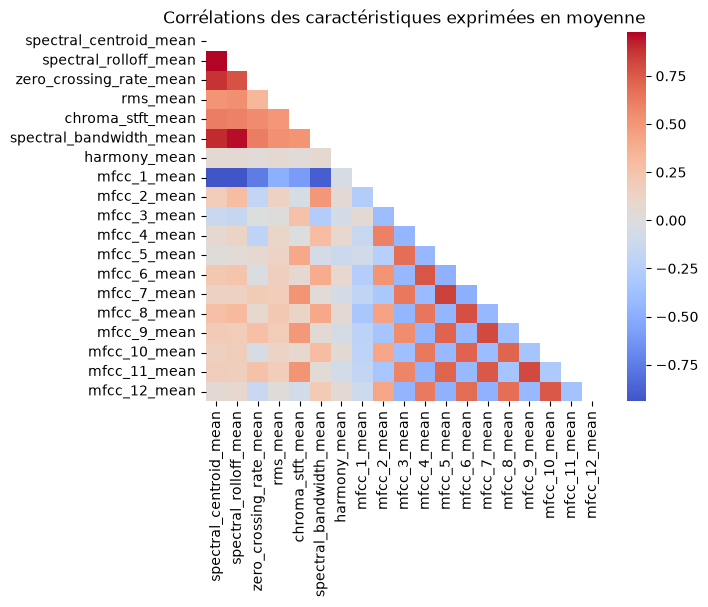

In [214]:
# corrélation des descripteurs 
mean_cols = [col for col in df.columns if "_mean" in col]
corr_mean = df[mean_cols].corr()
plt.title("Corrélations des caractéristiques exprimées en moyenne")
mask_vis = np.triu(np.ones_like(corr_mean, dtype=bool))
sns.heatmap(corr_mean, mask=mask_vis, cmap="coolwarm", center=0)
plt.show()

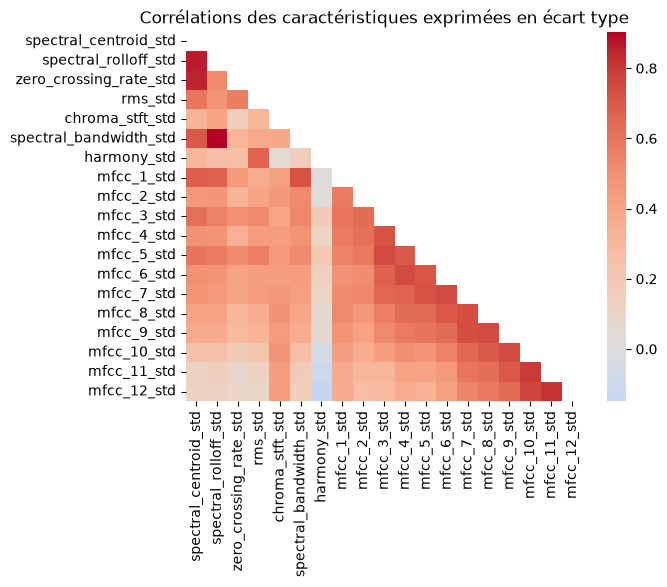

In [215]:
# corrélation des descripteurs 
std_cols = [col for col in df.columns if "_std" in col]
corr_std = df[std_cols].corr()
plt.title("Corrélations des caractéristiques exprimées en écart type")
mask_vis = np.triu(np.ones_like(corr_std, dtype=bool))
sns.heatmap(corr_std, mask=mask_vis, cmap="coolwarm", center=0)
plt.show()

Ces matrices de corrélation mettent en évidence plusieurs paires de variables fortement `corrélées`.
Cette observation révèle une certaine `redondance` de l'information contenue dans les caractéristiques audio extraites.
En effet, les corrélations élevées observées suggèrent que certaines variables capturent des aspects `similaires`,voire très proches, du signal musical. Cette redondance est particulièrement visible parmi certaines caractéristiques
spectrales et `coefficients MFCC`, qui décrivent des propriétés fréquentielles apparentées.
À l'inverse, de nombreuses variables présentent des corrélations faibles ou modérées,ce qui indique qu'elles
apportent des informations complémentaires et potentiellement utiles à la discrimination des genres musicaux.


In [216]:
# comportement du genre en fonc  tion des caractéristiques
# boxplot
def boxplot(variable_x,variable_y,data):
    plt.figure(figsize=(12,6))
    sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')
    plt.xticks(rotation=45)
    plt.title(f"Boxplot de {variable_y} selon {variable_x}",fontsize=15,fontweight="bold")
    plt.xticks(fontsize = 14)
    plt.yticks(fontsize = 10)
    plt.xlabel(variable_x,fontsize=15)
    plt.ylabel(variable_y,fontsize=15)
    plt.show()

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


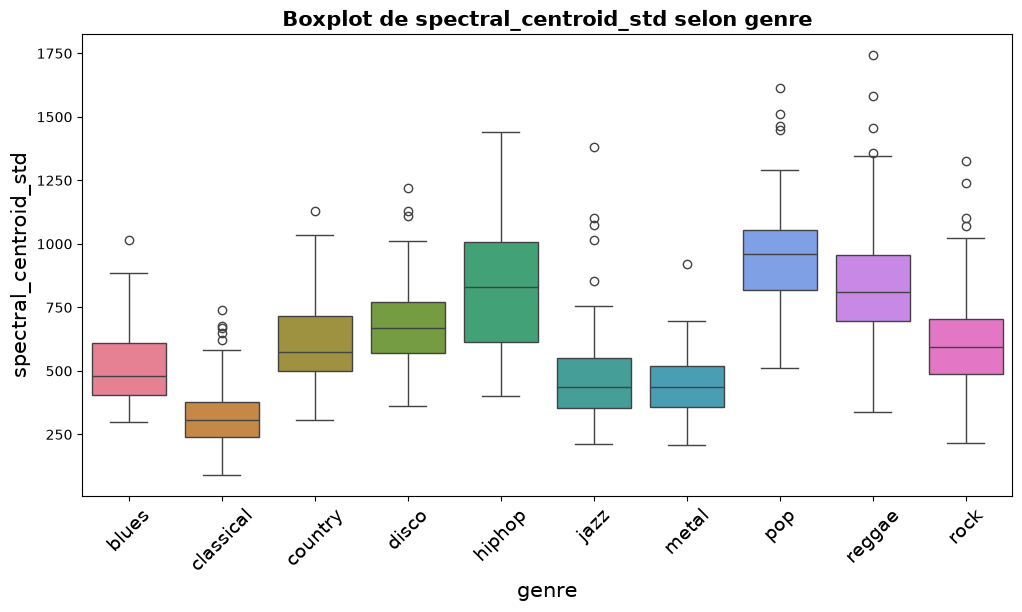

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


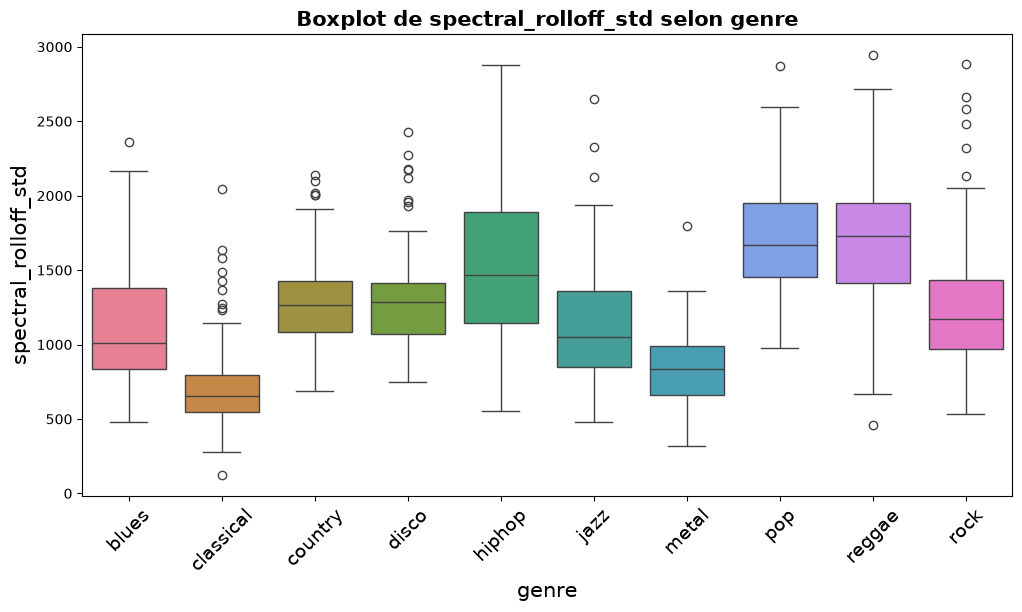

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


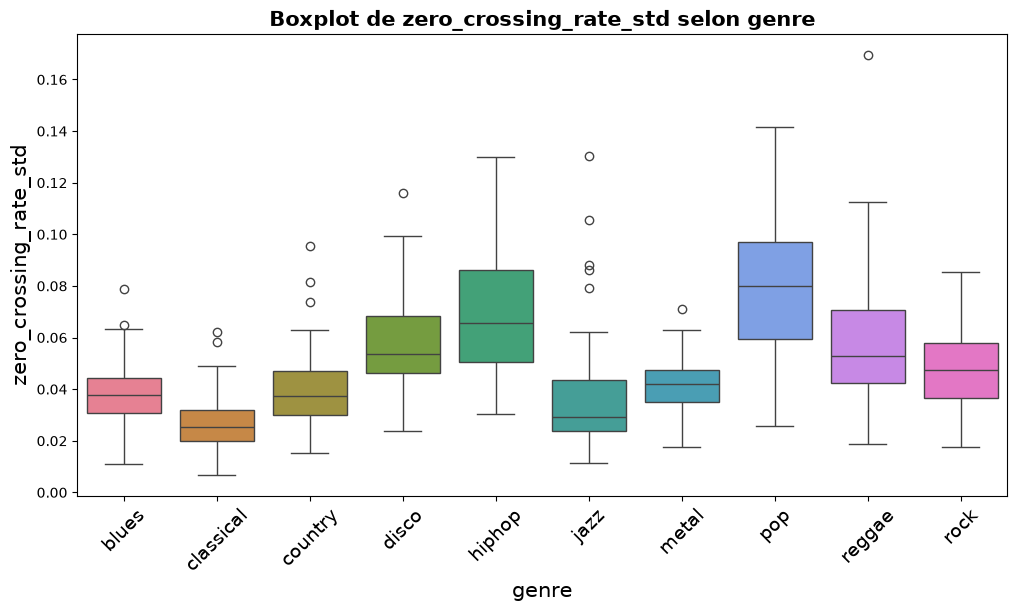

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


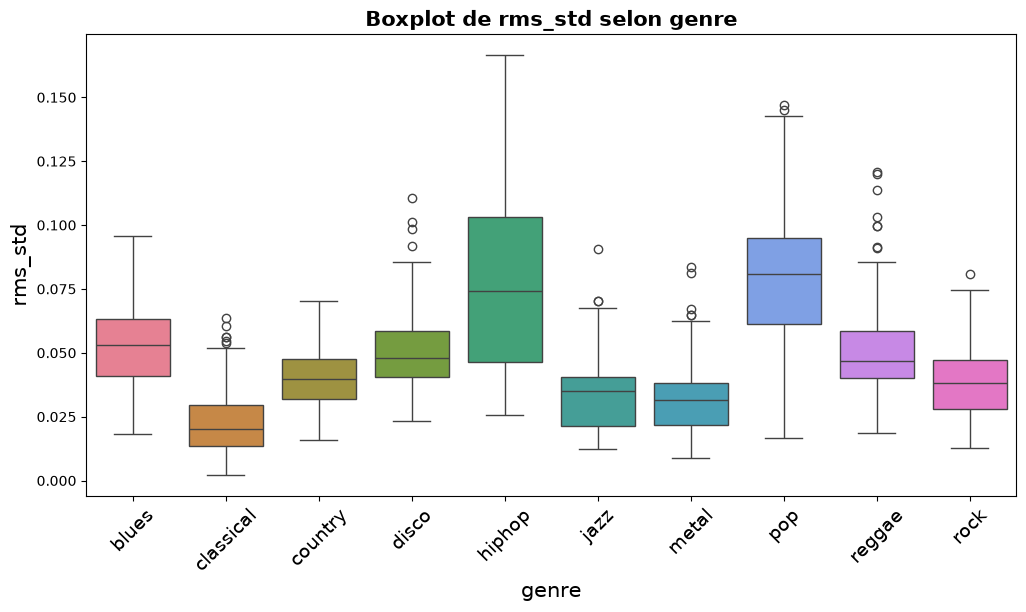

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


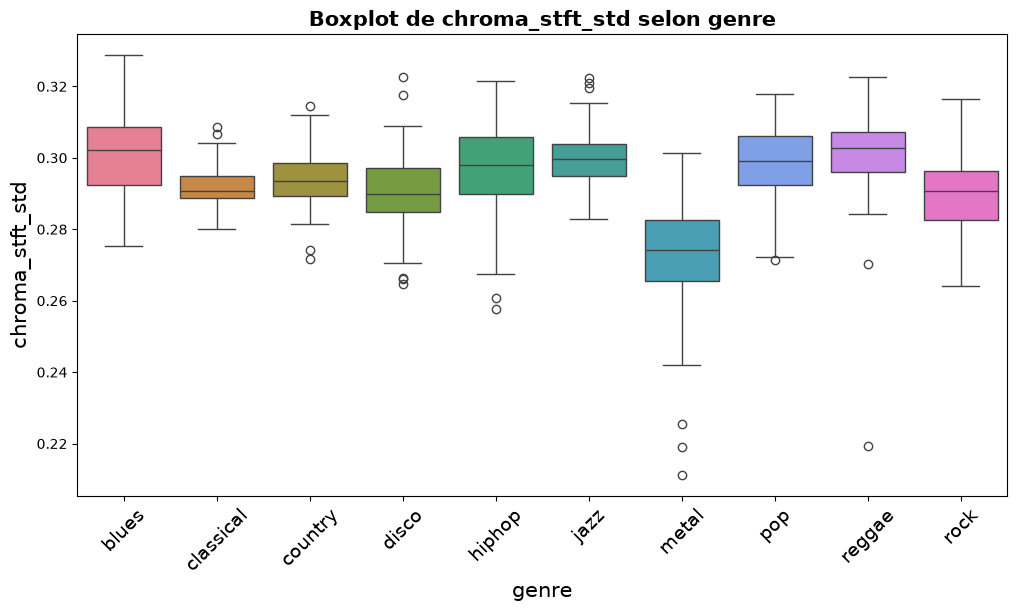

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


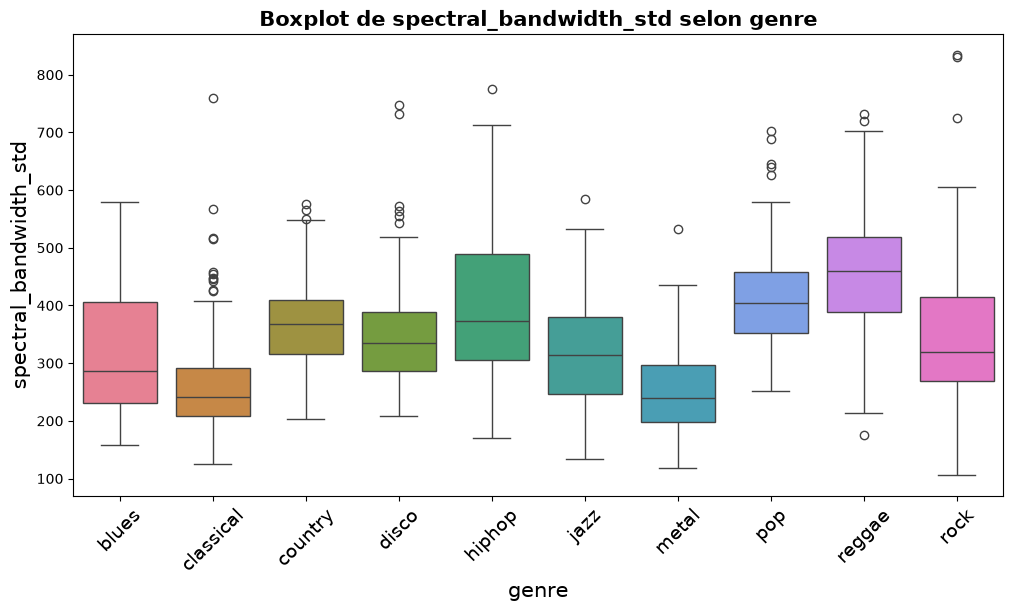

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


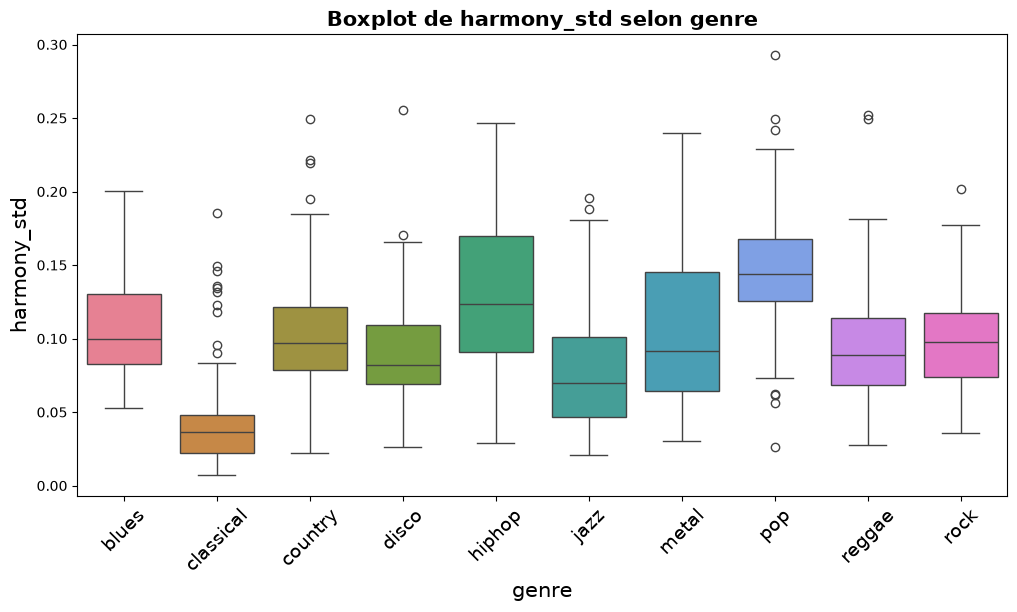

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


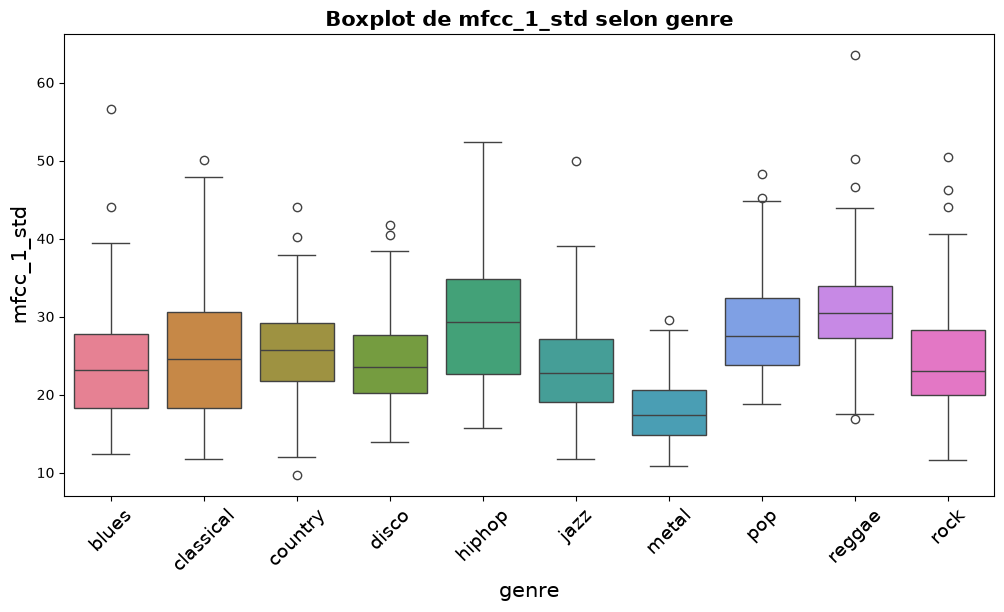

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


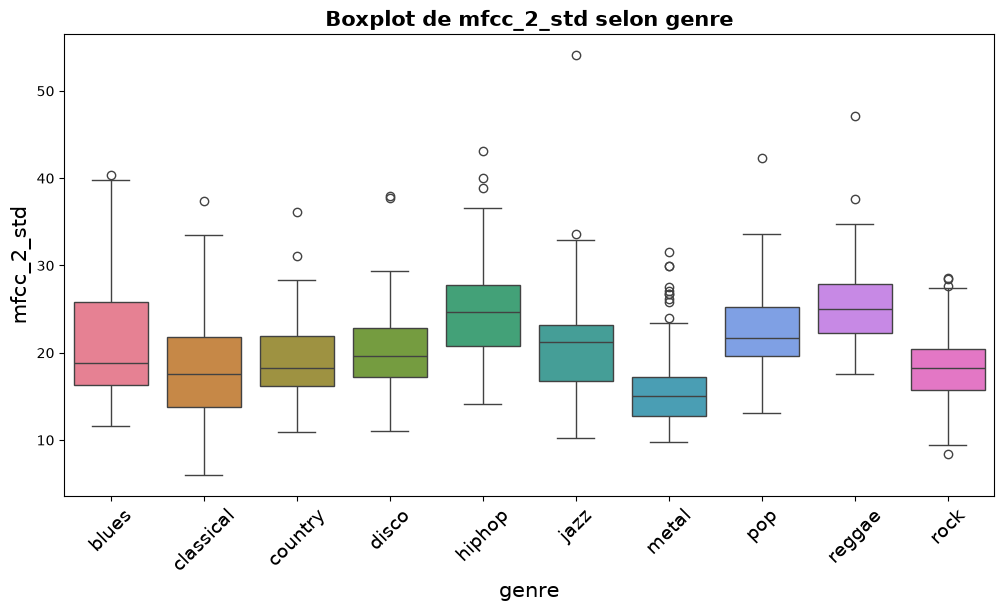

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


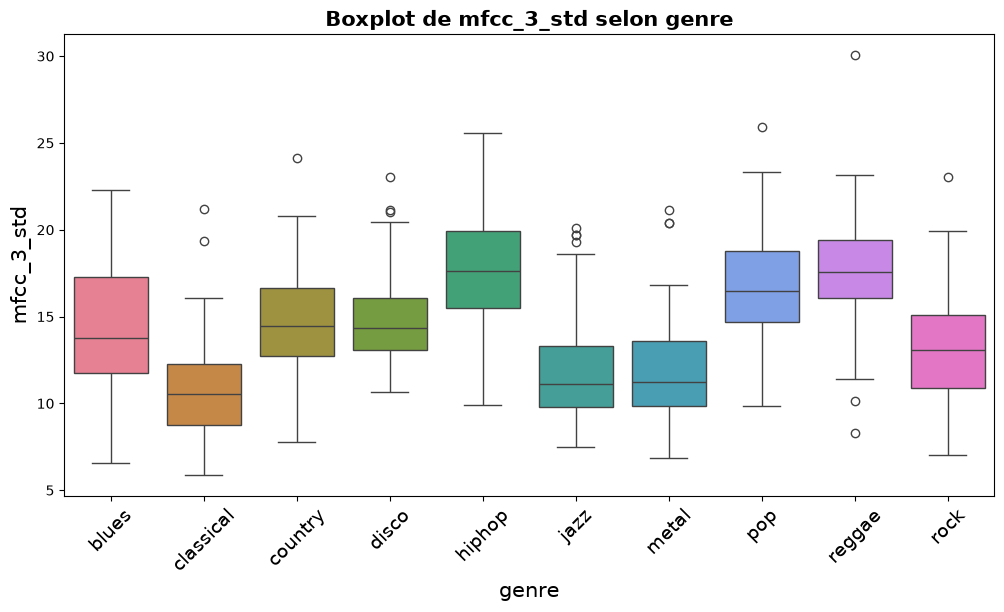

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


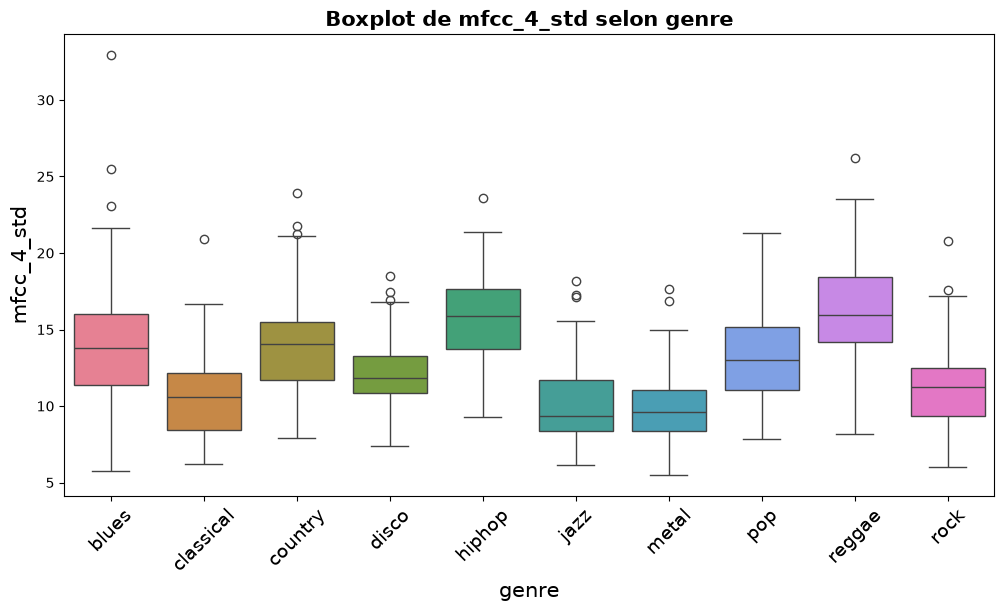

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


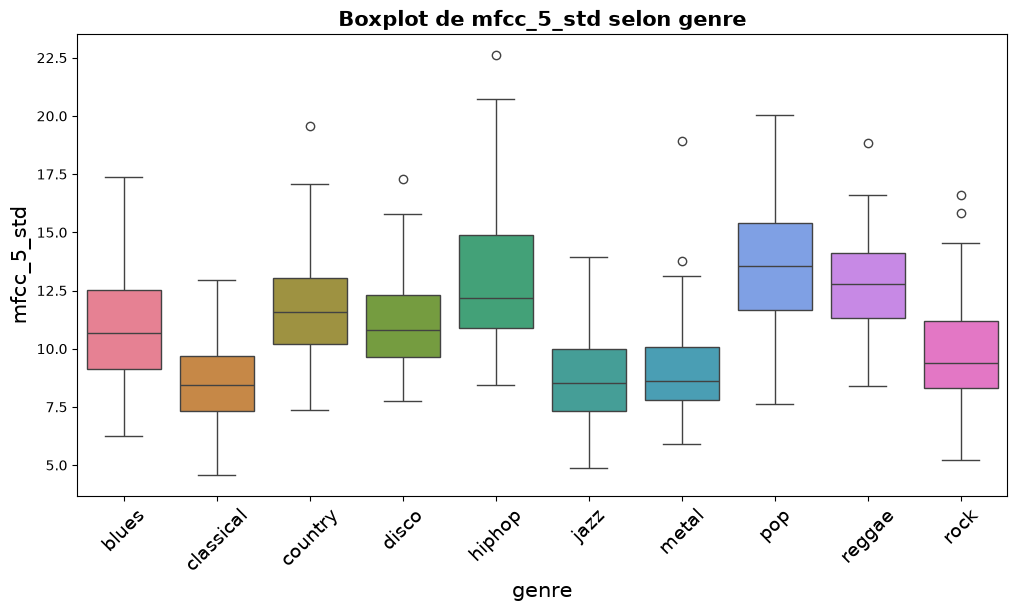

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


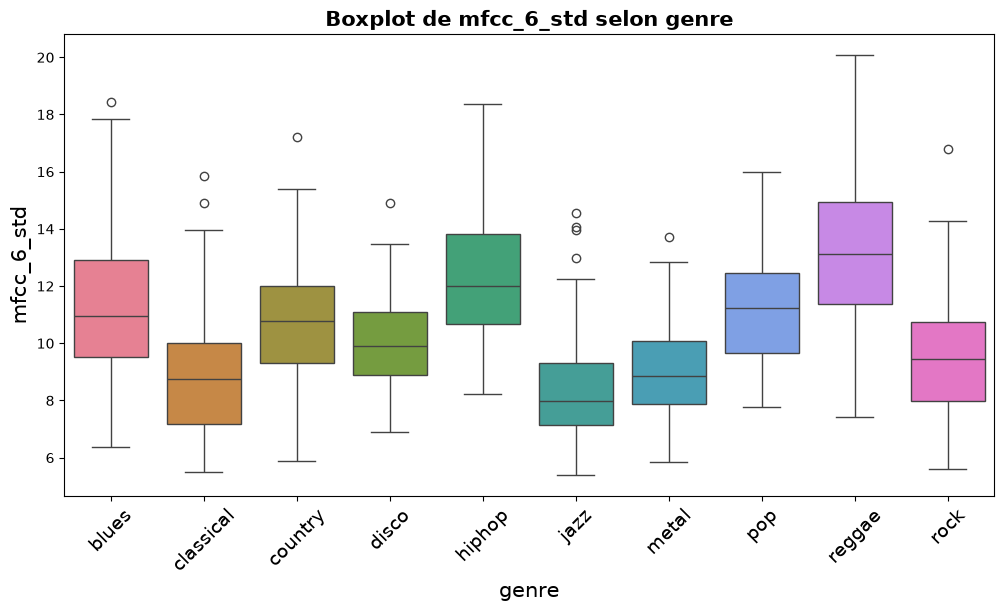

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


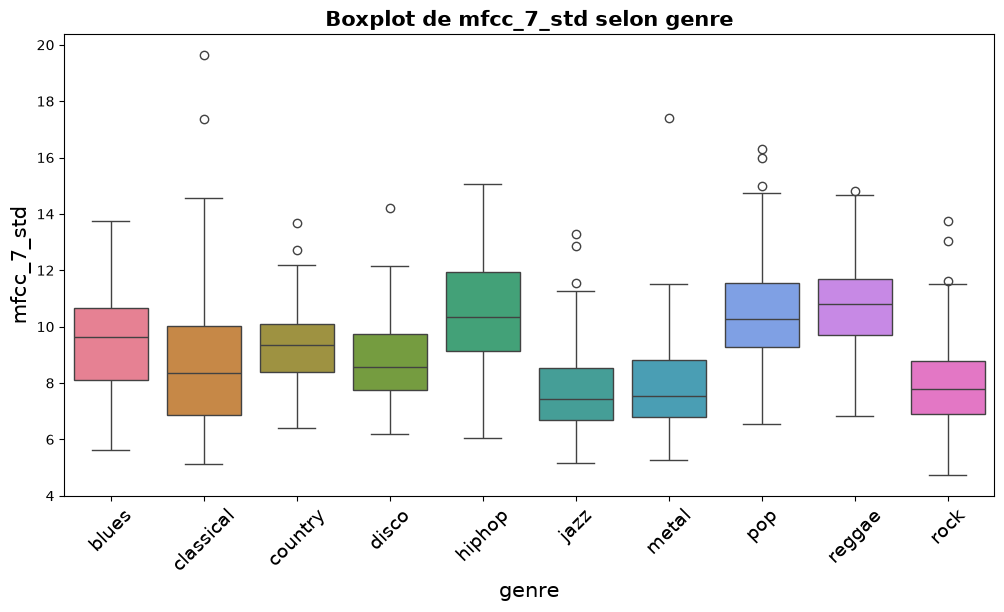

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


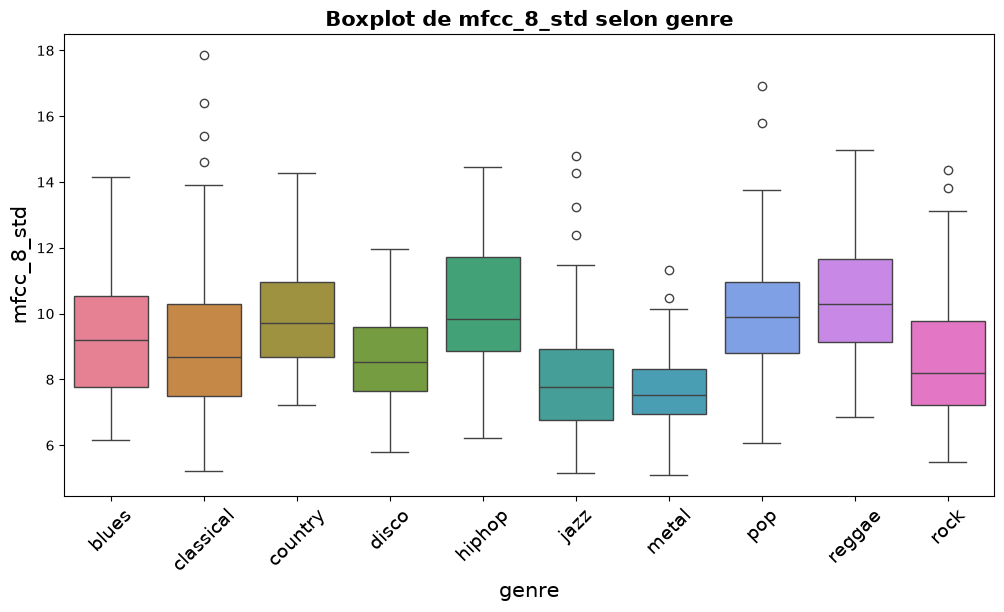

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


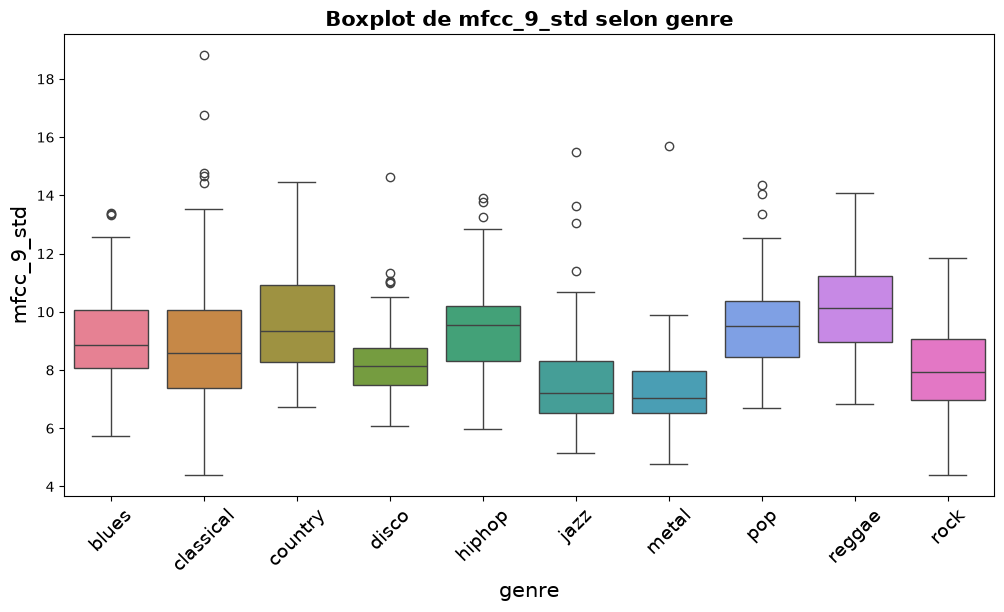

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


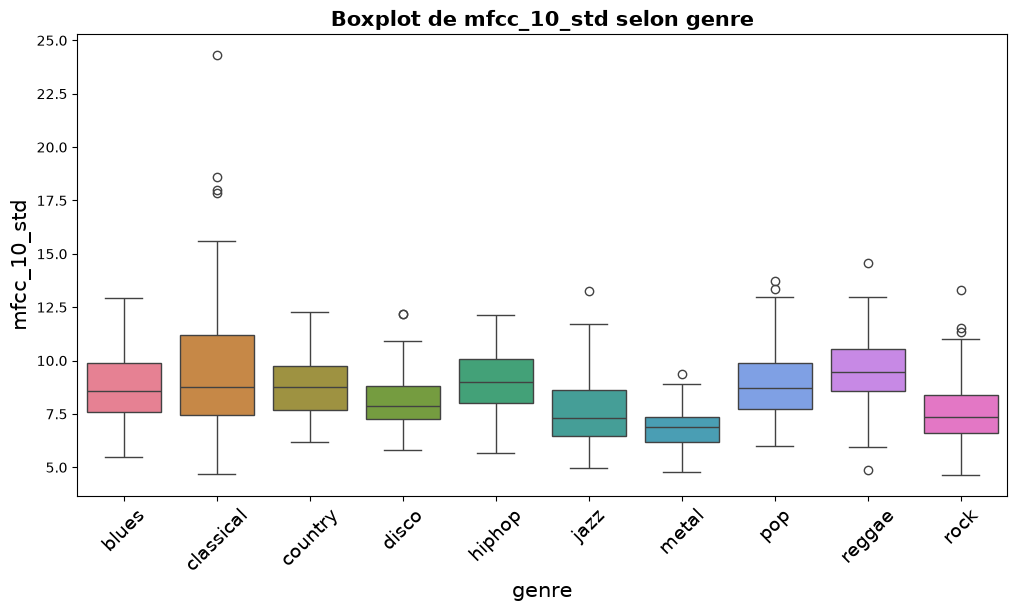

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


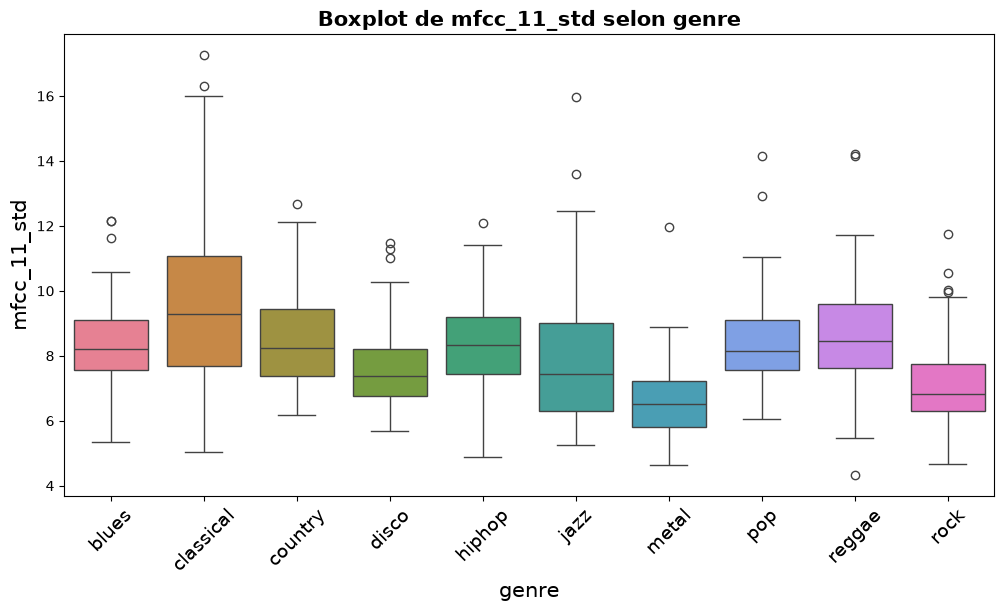

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


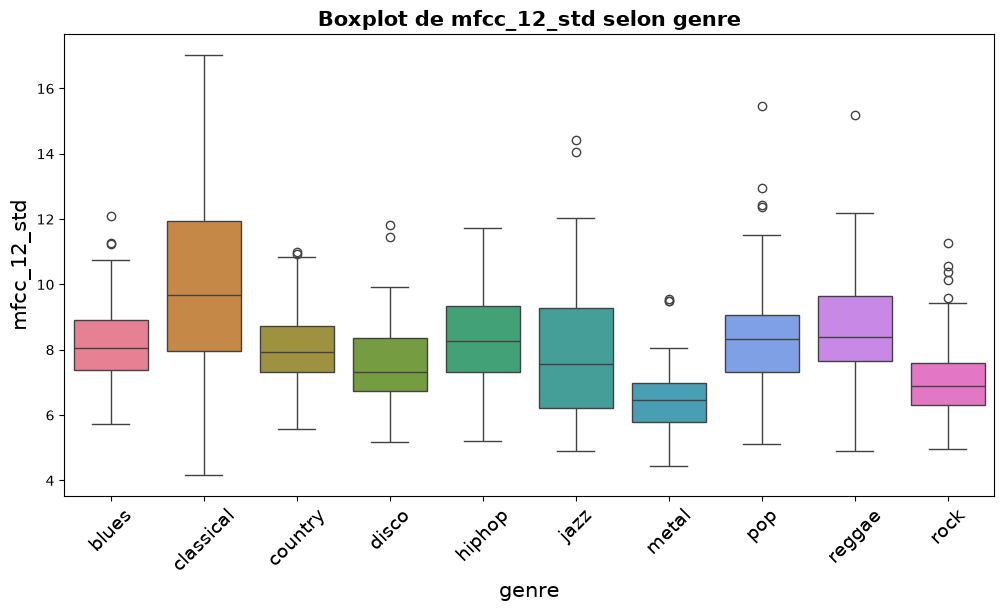

In [217]:
#echantillon de variables explicatives pour le boxplot
echantillon = [var for var in std_cols]
for i in echantillon:
    boxplot(variable_x = "genre",variable_y=i,data=df)


Avec ces graphiques , on observe des médianes qui sont globalement différentes.Ce qui souligne chez les variables/descripteurs en écart type  une possibilité de contribution à la séparation de genres musicaux.Toutefois,certaines variables chroma_ssf_std par exemple semblent ne pas avoir des différences assez significatives au niveau des médianes de certains genres:ceci témoigne de la ressemblanbce de certains morceau ainsi.


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


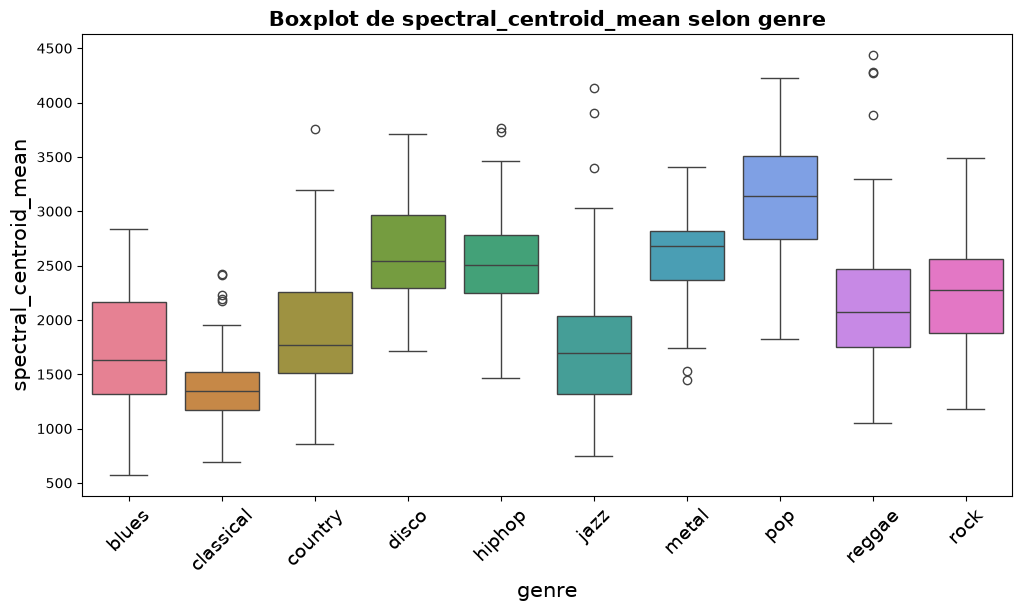

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


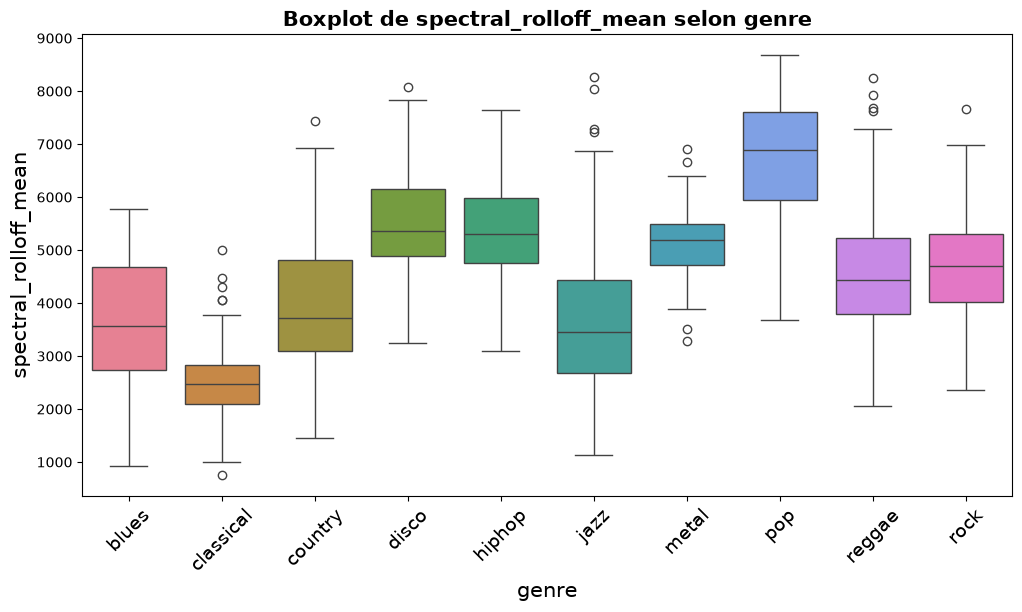

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


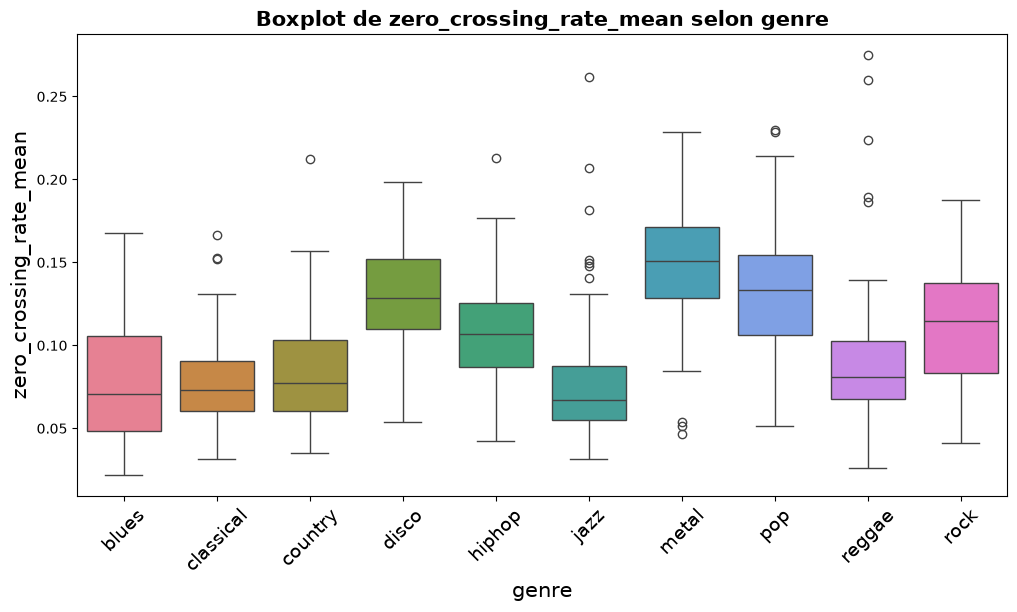

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


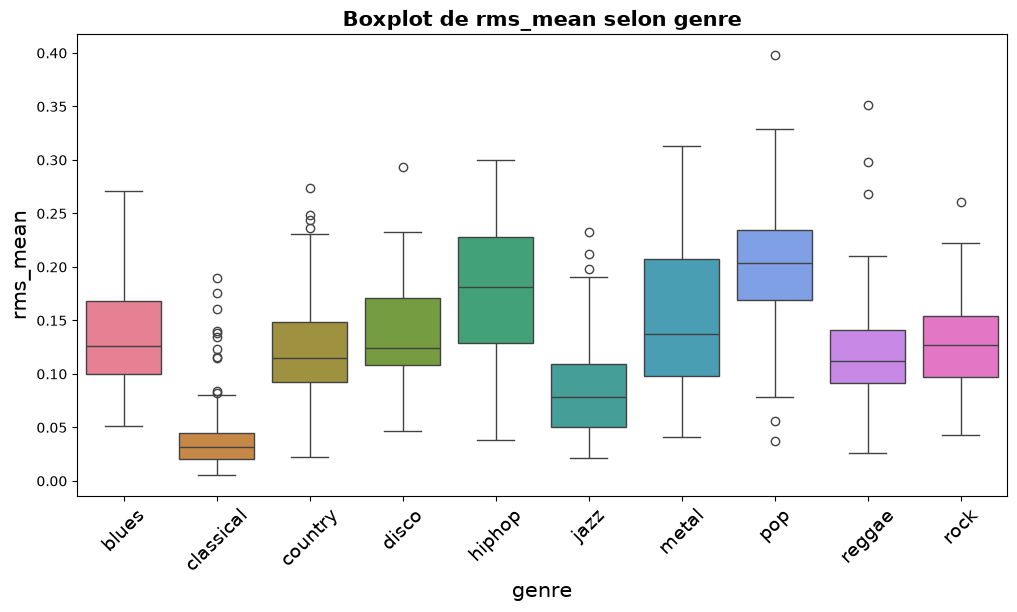

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


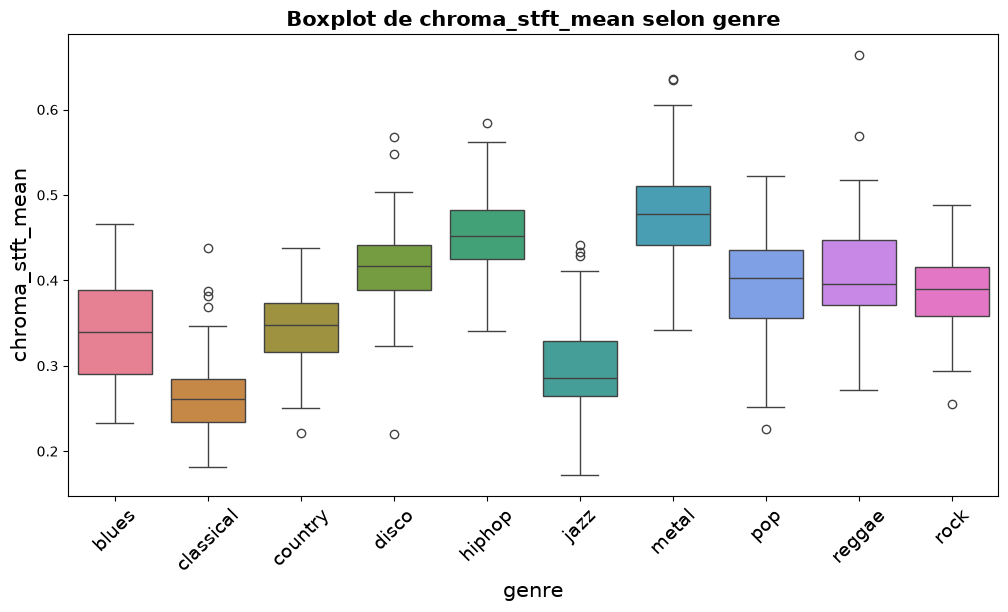

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


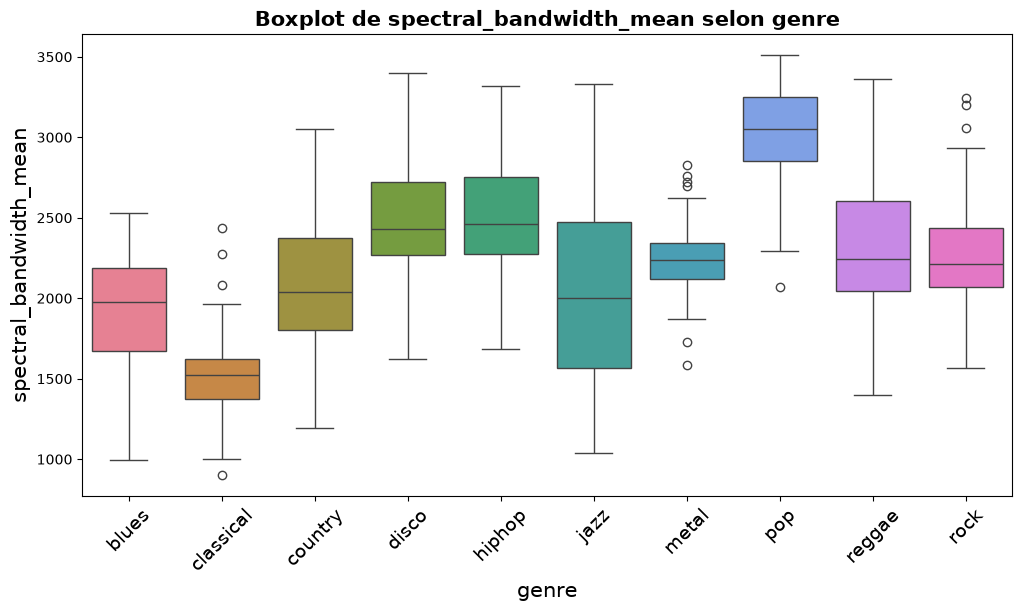

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_21764\1811775303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=variable_x,y=variable_y,data=data,palette='husl')


KeyboardInterrupt: 

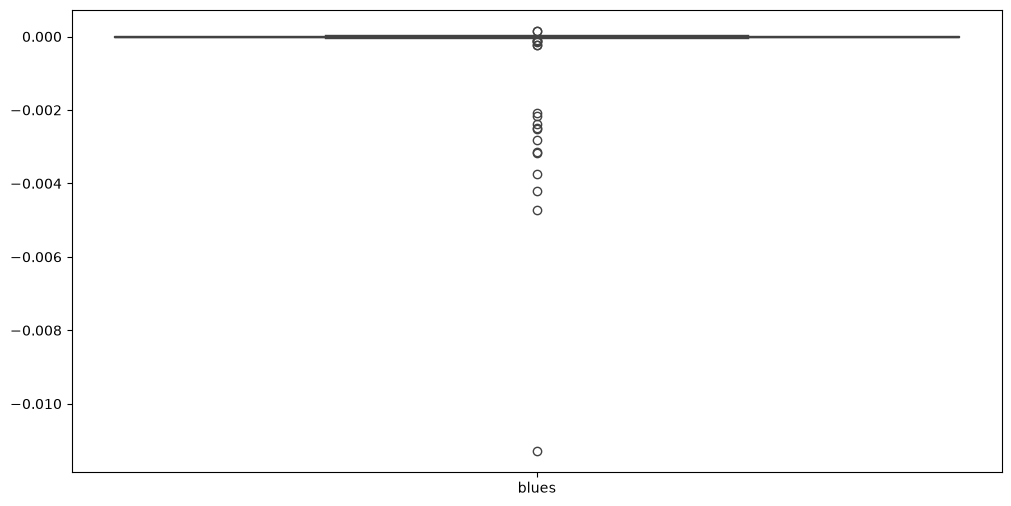

In [218]:
#echantillon de variables explicatives pour le boxplot
echantillon2 = [var for var in mean_cols ]
for i in echantillon2:
    boxplot(variable_x = "genre",variable_y=i,data=df)
    


D'après cette série de boxplots, on observe deux tendances principales.
Un premier groupe de descripteurs présente des médianes sensiblement
différentes selon les genres musicaux, ce qui suggère un potentiel 
pouvoir discriminatoire chez ces derniers.À l'inverse,on a harmony_mean  le seul dans ce groupe présentant  des médianes relativement proches d'un genre à l'autre.
Cette observation laisse à croire que, prise isolément, cette variable offre
une capacité de séparation plus limitée ou quasi-inexistante entre les genres musicaux  bien que harmony_std soit discriminatrice.

In [ ]:
X = df.drop(columns = ["nom_fichier","genre"])
y = df["genre"]
print(f'X.shape :{X.shape}')
print(f'y.shape :{y.shape}')


X.shape :(1000, 39)
y.shape :(1000,)


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler , StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split

In [ ]:
def encodage(y,y2):
    encoder = LabelEncoder()
    y= encoder.fit_transform(y)
    y2= encoder.transform(y2)
    return y,y2

In [ ]:
def scaling(X,X2):
    scaler=StandardScaler()
    X= scaler.fit_transform(X)
    X2 = scaler.transform(X2)
    return X,X2

In [ ]:
def preprocessing(X,X2,y,y2):
    y,y2= encodage(y,y2)
    X,X2= scaling(X,X2)
    return X,X2,y,y2

In [ ]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,
                                     random_state=42,stratify=y)

In [ ]:
X_train_scaled , X_test_scaled , y_train_encoded , y_test_encoded = preprocessing(X_train ,
                                 X_test ,y_train , y_test)

In [ ]:
print(X_train_scaled.shape,y_train_encoded.shape)
print(X_test_scaled.shape,y_test_encoded.shape)

(800, 39) (800,)
(200, 39) (200,)


In [229]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score,classification_report,confusion_matrix,accuracy_score,recall_score

In [230]:

XGB_model = XGBClassifier()
SVC_model = SVC()
RandomF_model = RandomForestClassifier(random_state = 42)
logistic_model = LogisticRegression()
DecisionTree_model =DecisionTreeClassifier()
KNN = KNeighborsClassifier(n_neighbors=8)


In [231]:
modeles = {"LogisticRegression"         :logistic_model,
            "DecisionTreeClassifier"    :DecisionTree_model,
                "RandomForestClassifier":RandomF_model,
                "SVC"                   : SVC_model,
                "KNeighborsClassifier"  :KNN,
           "XGBClassifier"              : XGB_model}

In [232]:
def evaluation(model,X_train,y_train,X_test,y_test):
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    score = f1_score(y_test,y_pred,average='macro')
    print("f1_score:",score)
    print("accuracy_score:",accuracy_score(y_test,y_pred))

In [233]:
for name,model in modeles.items():
    print(name,"...")
    evaluation(model,X_train_scaled,y_train_encoded,X_test_scaled,y_test_encoded)


LogisticRegression ...
f1_score: 0.6863501851562155
accuracy_score: 0.69
DecisionTreeClassifier ...
f1_score: 0.4195288200814926
accuracy_score: 0.425
RandomForestClassifier ...
f1_score: 0.6836310349053282
accuracy_score: 0.685
SVC ...
f1_score: 0.7104128085578664
accuracy_score: 0.71
KNeighborsClassifier ...
f1_score: 0.7256399456399456
accuracy_score: 0.725
XGBClassifier ...
f1_score: 0.6923812151146475
accuracy_score: 0.7


Après cette évaluation sans aucun traitement particulier des variables,
les modèles les plus performants sont : KNN,SVC,Xgboost,LogisticRegression.



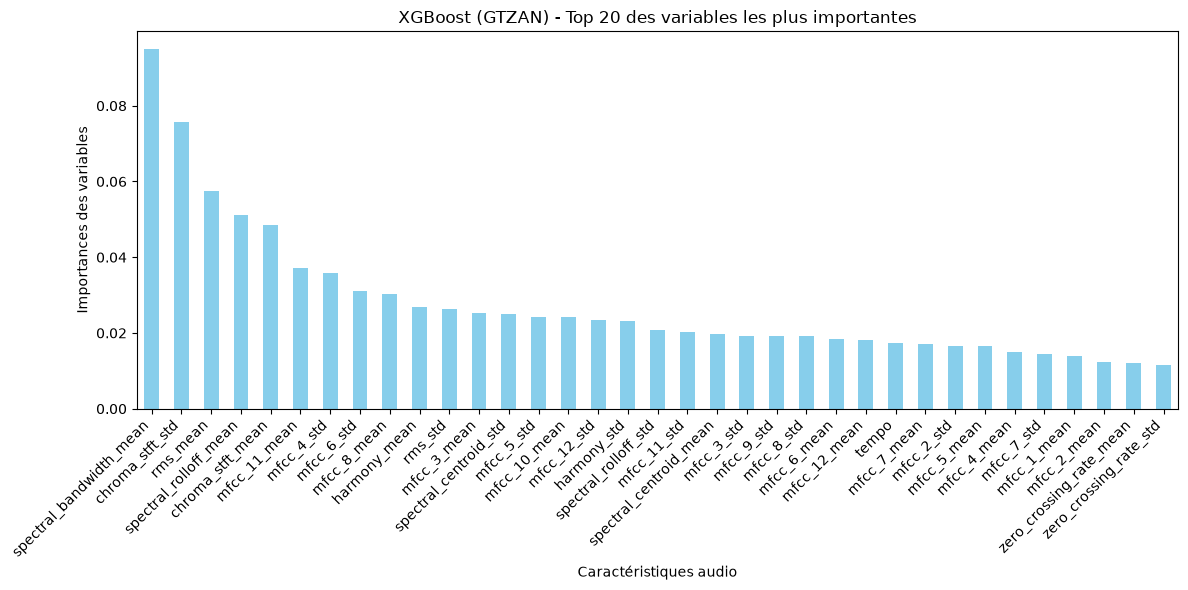

In [236]:
# Extraction des variables importantes triées par ordre décroissant pour XgbClassifier
xgb_importances = pd.Series(XGB_model.feature_importances_, 
        index=df.drop(columns=["nom_fichier","genre"]).columns)
# On trie et 35 premières variables importantes pour Xgbosst bien entendu
xgb_importances_trie = xgb_importances.sort_values(ascending=False).head(35)

plt.figure(figsize=(12, 6))
xgb_importances_trie.plot(kind="bar", color="skyblue") 

plt.title("XGBoost (GTZAN) - Top 20 des variables les plus importantes")
plt.ylabel("Importances des variables") 
plt.xlabel("Caractéristiques audio")
# Rotation à 45 degrés des noms des variables pour éviter qu'ils ne se chevauchent
plt.xticks(rotation=45, ha="right") 
plt.tight_layout()
plt.show()



In [237]:
alpha=35 # on garde les alpha descripteurs les plus importants
top_descripteurs = xgb_importances_trie.index[:35].tolist()

In [238]:
# CONVERTION EN DF POUR LA SEPARATION 
X_train = pd.DataFrame(X_train,columns=X.columns)
X_test = pd.DataFrame(X_test,columns=X.columns)


In [239]:

X_train_reduit=X_train[top_descripteurs] 
X_train_reduit = X_train[top_descripteurs]
X_test_reduit  = X_test[top_descripteurs]

In [240]:
X_train_reduit, X_test_reduit = scaling(X_train_reduit,X_test_reduit)


In [241]:
for name,model in modeles.items():
    print(name,"...")
    evaluation(model,X_train_reduit,y_train_scaled,X_test_reduit,y_test_scaled)

LogisticRegression ...
f1_score: 0.68722993739295
accuracy_score: 0.69
DecisionTreeClassifier ...
f1_score: 0.4570834641523539
accuracy_score: 0.46
RandomForestClassifier ...
f1_score: 0.6804545943148945
accuracy_score: 0.685
SVC ...
f1_score: 0.7308093126385808
accuracy_score: 0.73
KNeighborsClassifier ...
f1_score: 0.7098752157884747
accuracy_score: 0.71
XGBClassifier ...
f1_score: 0.7111598463172484
accuracy_score: 0.72


La selection des 35 variables  les plus importantes 
pour le modèle de XGBOOST  a été favorable
pour tous ces  modèles.
.


# Recherche en grille

In [253]:

def recherche_grille(model, param, X_train_scaled, y_train_encoded,X_test_scaled,y_test_encoded):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid = GridSearchCV(estimator=model,param_grid=param,
    cv=cv,scoring='f1_macro',n_jobs=-1,verbose=0)
    grid.fit(X_train_scaled, y_train_encoded)
    print("Meilleur score :", grid.best_score_)
    print("Meilleurs paramètres :", grid.best_params_)
    print("test :", grid.score(X_test_scaled, y_test_encoded)) 
    return grid.best_estimator_


In [260]:
logistic_reg_param = {"C":[0.001,0.01,0.1,1,10,100],"solver":["lbfgs","liblinear"],
                      "penalty":["l2"],"max_iter":[200,500,750,850,1000]}
svc_param = {"C":[0.1,1,3,10,30,50,100],"kernel":["rbf"],
    "gamma":[0.001,0.003,0.01,0.03,0.1,"scale","auto"]}

KNN_param = {"n_neighbors":[3,5,7,8,9,11,13],
    "weights":["uniform","distance"],"p":[1,2]}



xgboost_param = {
    'n_estimators':     [200, 400],
    'max_depth':        [3, 5],
    'learning_rate':    [0.05, 0.1],
    'subsample':        [0.7, 1.0],
    'colsample_bytree': [0.5, 0.8],
}



In [265]:
#SVC
BestSVC=recherche_grille(modeles["SVC"], svc_param, X_train_scaled, y_train_encoded,X_test_scaled,y_test_encoded)

Meilleur score : 0.7382882778548912
Meilleurs paramètres : {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
test : 0.7579892255492992


In [266]:
#KNN
BestKNN = recherche_grille(modeles["KNeighborsClassifier"], KNN_param, X_train_scaled, y_train_encoded,X_test_scaled,y_test_encoded)


Meilleur score : 0.6606620223077497
Meilleurs paramètres : {'n_neighbors': 5, 'p': 1, 'weights': 'distance'}
test : 0.730450734805677


In [267]:

BestXGB = recherche_grille(modeles["XGBClassifier"], xgboost_param, X_train_scaled, y_train_encoded,X_test_scaled,y_test_encoded)


Meilleur score : 0.725007165020366
Meilleurs paramètres : {'colsample_bytree': 0.5, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 400, 'subsample': 0.7}
test : 0.7448005987512509


In [271]:
print("BestSVC")
evaluation(BestSVC,X_train_scaled,y_train_encoded,X_test_scaled,y_test_encoded)

print("BestXGB")
evaluation(BestXGB,X_train_scaled,y_train_encoded,X_test_scaled,y_test_encoded)

print("BestKNN")
evaluation(BestKNN,X_train_scaled,y_train_encoded,X_test_scaled,y_test_encoded)

BestSVC
f1_score: 0.7579892255492992
accuracy_score: 0.76
BestXGB
f1_score: 0.7448005987512509
accuracy_score: 0.745
BestKNN
f1_score: 0.730450734805677
accuracy_score: 0.73


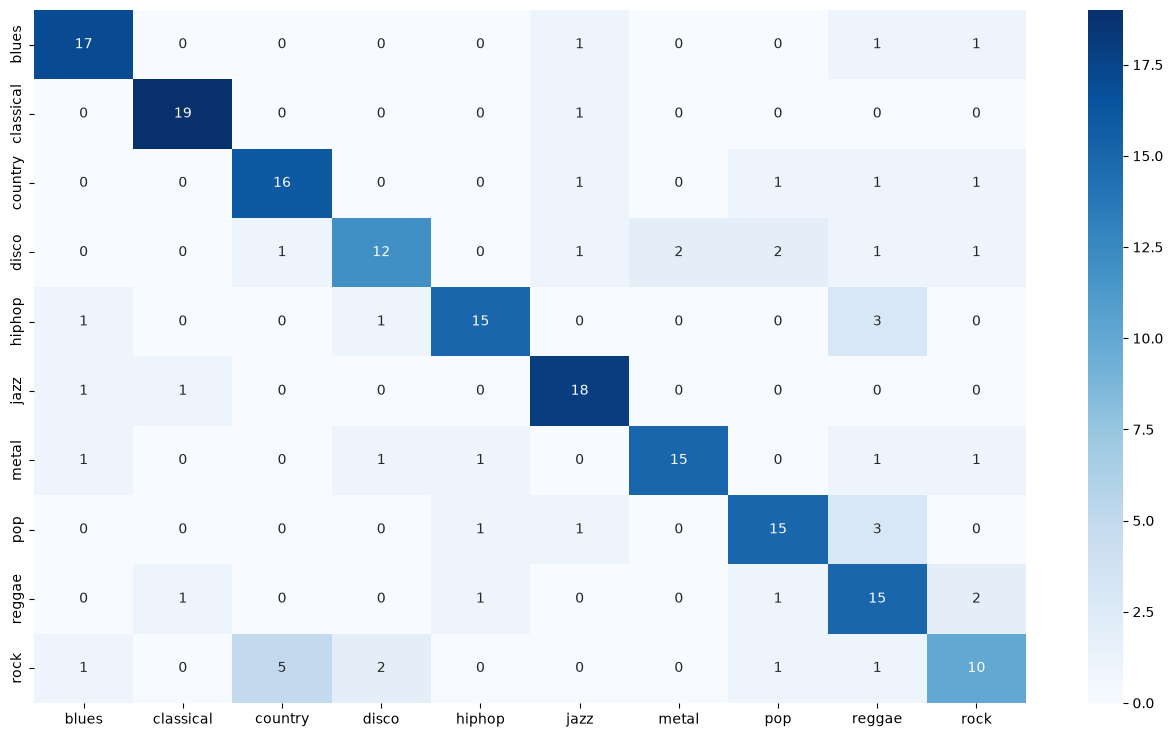

In [276]:
BestSVC.fit(X_train_scaled,y_train_encoded)
y_pred = BestSVC.predict(X_test_scaled)
#score = f1_score(y_test,y_pred,average='macro')
confusion_matr = confusion_matrix(y_test_encoded, y_pred) 
plt.figure(figsize = (16, 9))
sns.heatmap(confusion_matr, cmap="Blues", annot=True, 
            xticklabels = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"],
           yticklabels=["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]);


In [ ]:
from features_extraction import extraire_features
def prediction(fichier): # entrez le chemin si nécessaire 
    features = extraire_features(fichier)
    



In [277]:
top_descripteurs

['spectral_bandwidth_mean',
 'chroma_stft_std',
 'rms_mean',
 'spectral_rolloff_mean',
 'chroma_stft_mean',
 'mfcc_11_mean',
 'mfcc_4_std',
 'mfcc_6_std',
 'mfcc_8_mean',
 'harmony_mean',
 'rms_std',
 'mfcc_3_mean',
 'spectral_centroid_std',
 'mfcc_5_std',
 'mfcc_10_mean',
 'mfcc_12_std',
 'harmony_std',
 'spectral_rolloff_std',
 'mfcc_11_std',
 'spectral_centroid_mean',
 'mfcc_3_std',
 'mfcc_9_std',
 'mfcc_8_std',
 'mfcc_6_mean',
 'mfcc_12_mean',
 'tempo',
 'mfcc_7_mean',
 'mfcc_2_std',
 'mfcc_5_mean',
 'mfcc_4_mean',
 'mfcc_7_std',
 'mfcc_1_mean',
 'mfcc_2_mean',
 'zero_crossing_rate_mean',
 'zero_crossing_rate_std']